# Data wrangling and exploratory analysis

Historical 90-row Falcon 9 sample. Class 1 includes controlled ocean outcomes and does not necessarily imply recovery.

In [1]:
from pathlib import Path
import os
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
os.chdir(root)
assert (root / 'data').is_dir(), 'Run from the repository root or notebooks directory.'

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('data/dataset_part_1.csv')
bad={'False ASDS','False Ocean','False RTLS','None ASDS','None None'}
df['Class']=(~df.Outcome.isin(bad)).astype(int)
reference=pd.read_csv('data/dataset_part_2.csv')
assert df.Class.equals(reference.Class)
print('Launches:',len(df),'Class 1:',df.Class.sum())
display(df.groupby('Outcome').Class.agg(['count','sum']))

Launches: 90 Class 1: 60


,count,sum
Outcome,,
False ASDS,6,0
False Ocean,2,0
False RTLS,1,0
None ASDS,2,0
None None,19,0
True ASDS,41,41
True Ocean,5,5
True RTLS,14,14


In [2]:
features=df[['FlightNumber','PayloadMass','Orbit','LaunchSite','Flights','GridFins','Reused','Legs','LandingPad','Block','ReusedCount','Serial']]
encoded=pd.get_dummies(features,columns=['Orbit','LaunchSite','LandingPad','Serial','GridFins','Reused','Legs'],dtype=float).astype(float)
saved=pd.read_csv('data/dataset_part_3.csv')
assert set(encoded.columns)==set(saved.columns)
assert encoded[saved.columns].equals(saved)
print('Encoded feature matrix:',encoded.shape)
display(df.groupby('LaunchSite').Class.agg(['count','sum','mean']))

Encoded feature matrix: (90, 83)


,count,sum,mean
LaunchSite,,,
CCAFS SLC 40,55,33,0.600000
KSC LC 39A,22,17,0.772727
VAFB SLC 4E,13,10,0.769231


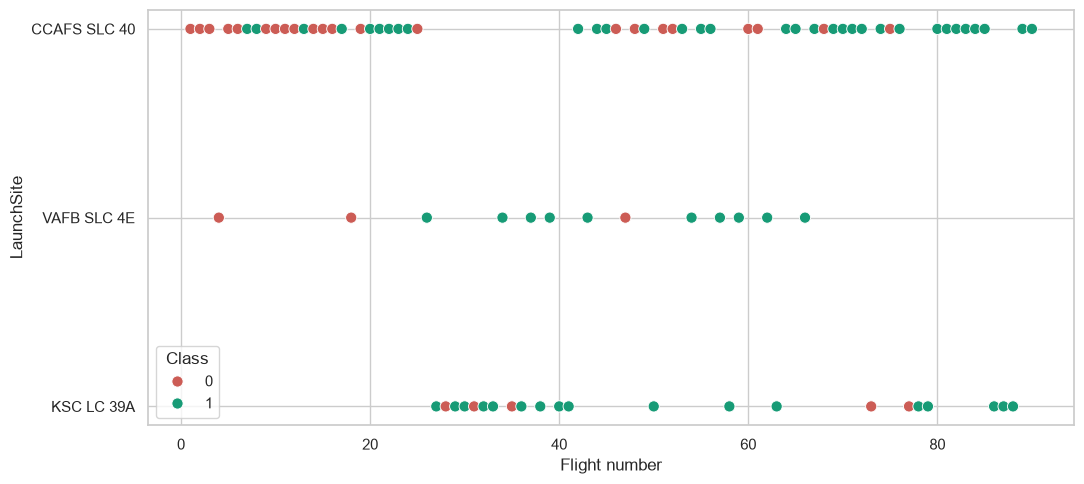

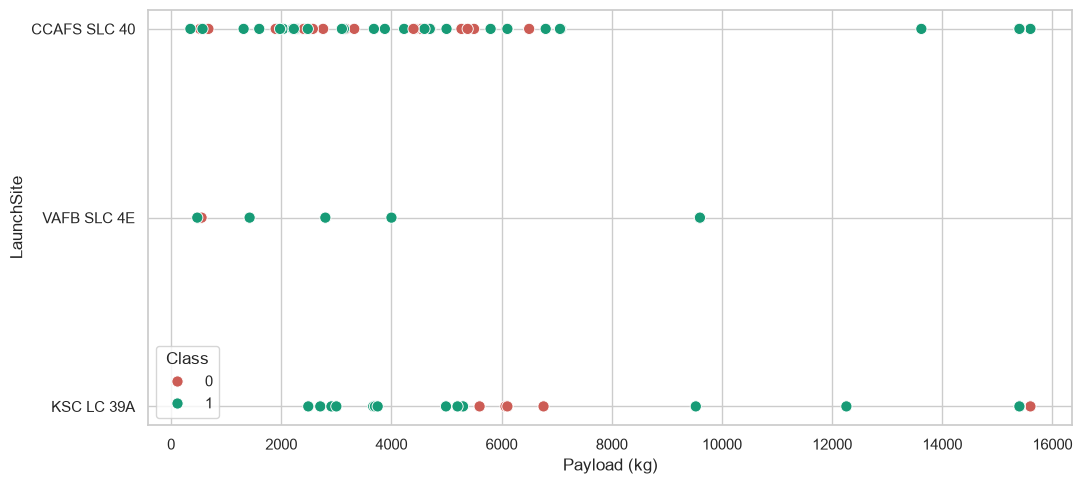

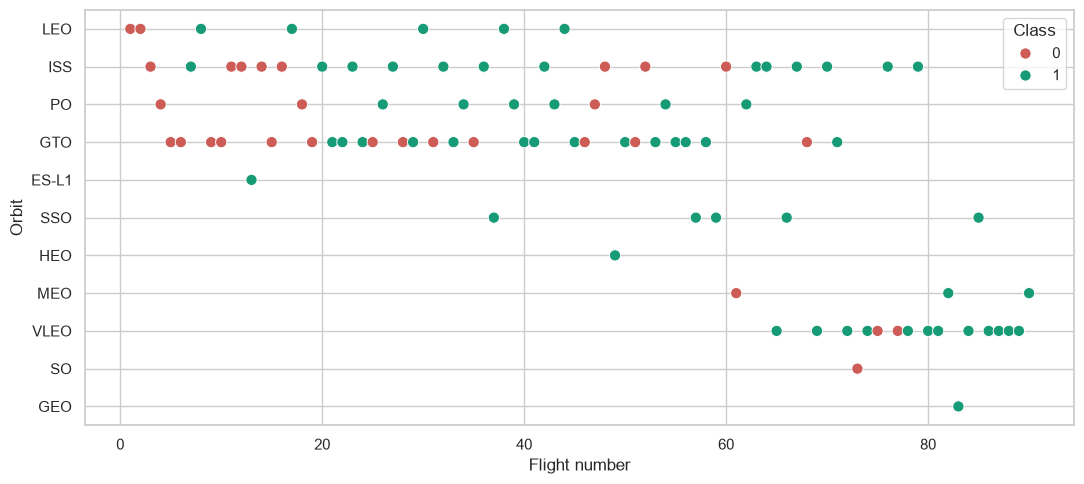

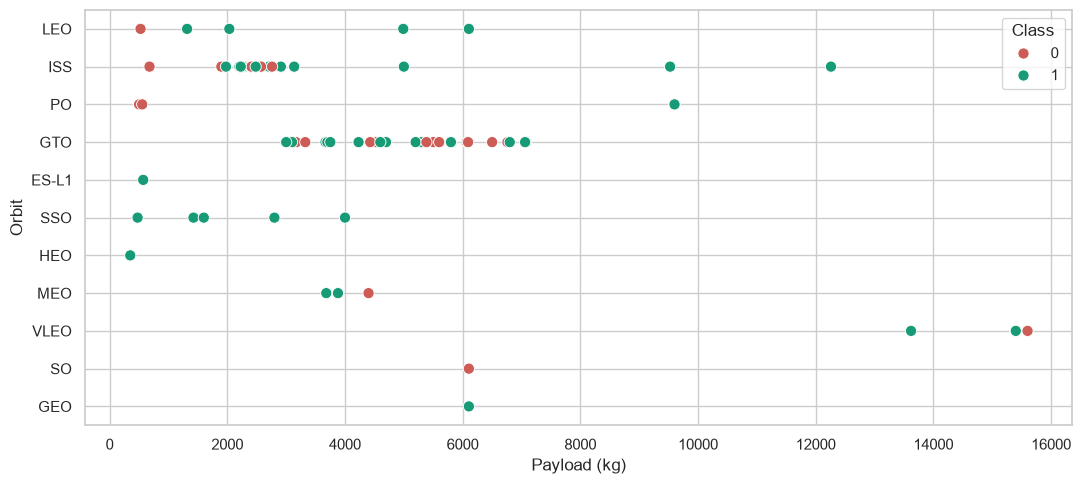

In [3]:
sns.set_theme(style='whitegrid')
for x,y in [('FlightNumber','LaunchSite'),('PayloadMass','LaunchSite'),('FlightNumber','Orbit'),('PayloadMass','Orbit')]:
    fig,ax=plt.subplots(figsize=(11,5))
    sns.scatterplot(data=df,x=x,y=y,hue='Class',palette={0:'#cc5c55',1:'#179b76'},ax=ax,s=65)
    ax.set_xlabel('Payload (kg)' if x=='PayloadMass' else 'Flight number')
    plt.tight_layout()
    plt.show()

,count,sum,mean
Orbit,,,
ES-L1,1,1,1.000000
GEO,1,1,1.000000
GTO,27,14,0.518519
HEO,1,1,1.000000
ISS,21,13,0.619048
LEO,7,5,0.714286
MEO,3,2,0.666667
PO,9,6,0.666667
SO,1,0,0.000000


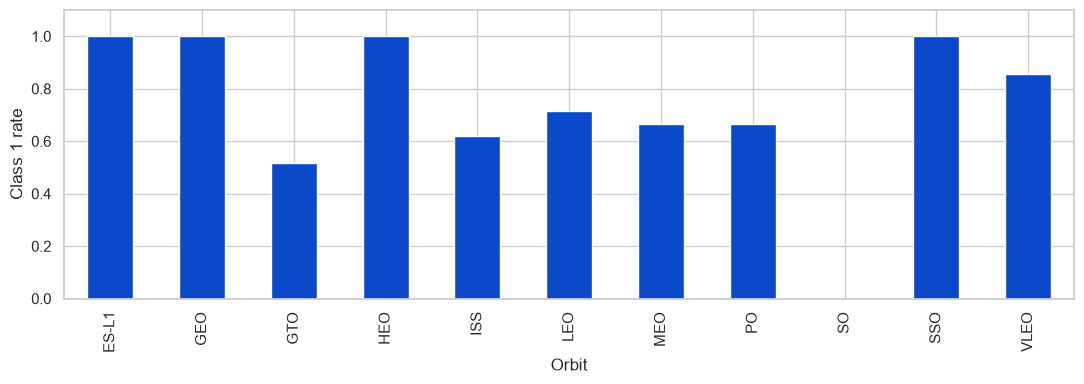

,count,sum,mean
Date,,,
2010,1,0,0.000000
2012,1,0,0.000000
2013,3,0,0.000000
2014,6,2,0.333333
2015,6,2,0.333333
2016,8,5,0.625000
2017,18,15,0.833333
2018,18,11,0.611111
2019,10,9,0.900000


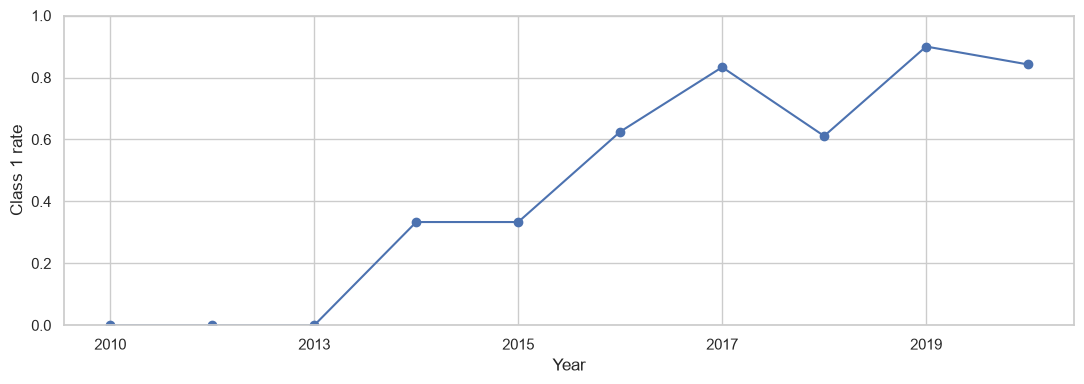

In [4]:
orbit=df.groupby('Orbit').Class.agg(['count','sum','mean'])
display(orbit)
ax=orbit['mean'].plot.bar(figsize=(11,4),color='#0B49CB')
ax.set_ylabel('Class 1 rate')
ax.set_ylim(0,1.1)
plt.tight_layout()
plt.show()
yearly=df.groupby(df.Date.str[:4]).Class.agg(['count','sum','mean'])
display(yearly)
yearly['mean'].plot(marker='o',figsize=(11,4),ylim=(0,1),ylabel='Class 1 rate',xlabel='Year')
plt.tight_layout()
plt.show()

## Interpretation
KSC records 17/22 Class 1 outcomes and CCAFS has 33, the largest count. SSO has 5/5 successes, but several 100% orbit groups have only one observation. These associations can reflect technology and mission mix. The pre-split scaling in the supplied classification lab limits its evaluation. A future study should fit preprocessing within training folds and hold out a later time period.